# Active subspaces of an impedance-fitting misfit for a grouped-parameter lithium-ion SPMe

Model and parameter study from: N. Hallemans, N. E. Courtier, C. P. Please, B. Planden, R. Dhoot, R. Timms, S. J. Chapman, D. Howey, S. R. Duncan, "Physics-Based Battery Model Parametrisation from Impedance Data", *Journal of The Electrochemical Society* 172(6) (2025) 060507, [doi:10.1149/1945-7111/add41b](https://doi.org/10.1149/1945-7111/add41b).

__Noël Hallemans__<sup>a,d</sup>, __Nicola E. Courtier__<sup>a,d</sup>, __Colin P. Please__<sup>b,d</sup>, __Brady Planden__<sup>a</sup>, __Rishit Dhoot__<sup>b</sup>, __Robert Timms__<sup>c</sup>, __S. Jon Chapman__<sup>b,d</sup>, __David Howey__<sup>a,d</sup>, __Stephen R. Duncan__<sup>a,d</sup>

<sup>a</sup> Department of Engineering Science, University of Oxford, Oxford, UK; <sup>b</sup> Mathematical Institute, University of Oxford, Oxford, UK; <sup>c</sup> Ionworks Technologies Inc, Pittsburgh, PA, USA; <sup>d</sup> The Faraday Institution, Harwell Campus, Didcot, UK

Notebook: Claude (Anthropic) for P. Constantine, 2026

(Affiliations as in the arXiv version, arXiv:2412.10896v4, which is the version read for this notebook; the citation is the published article.)

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import subspace_angles
from scipy.stats import spearmanr
from IPython.display import Markdown, display
import active_subspaces as ac
import spme_eis_driver as se   # constants only; running the model needs PyBaMM and PyBOP (see DATA.md)

warnings.formatwarning = lambda msg, cat, *args, **kwargs: f'{cat.__name__}: {msg}\n'   # warnings without file paths

SEED = 2025
t_start = time.perf_counter()

## Summary

We computed the paper's least-squares impedance misfit $\Phi$ (Eq. 7: nine SOCs, 60 frequencies from 200 µHz to 1 kHz) for the grouped-parameter SPMe with double-layer capacitance (PyBOP's `GroupedSPMe`, impedance by PyBaMM's frequency-domain EIS method) against noise-free synthetic spectra at the paper's true parameters, at 1000 Monte Carlo samples of the 18 grouped parameters, uniform on the optimisation box of Table 3, with exact adjoint gradients. The QoI $\log_{10}\Phi$ has a one-dimensional active subspace ($\lambda_1/\lambda_2 = 23.6$, bootstrap 16.9–32.4), made of the series resistance and the two charge-transfer time scales, which carry 90 % of $\mathrm{trace}(\mathbf C)$, and a cubic in that one variable predicts $\log_{10}\Phi$ with leave-one-out $R^2 = 0.91$; reweighting the samples to log-uniform time scales lowers the ratio to 5.2 but keeps the direction. The global and local views agree: at the truth the leading eigenvector of the misfit's Gauss–Newton matrix is $\mathbf w_1$ (5.9° apart), the weakest directions of both lie in the span of the electrolyte-diffusion groups, which the paper found hard to identify, and $t^+$, which the paper estimated well; and both rankings follow the errors of the paper's best fit (Table 3), the local (Cramér–Rao) ranking more closely (Spearman 0.88, much of it the split between the two groups) than the global shares (0.59); the model at the paper's printed best fit reproduces its Table 3 fitting errors once $\hat R_0$ is placed within its print rounding.

## Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs, normalized to $[-1,1]^m$ with a uniform density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\boldsymbol\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf z = \mathbf W_2^T\mathbf x$; a plot of $f$ against $\mathbf y$ (a sufficient summary plot) shows the structure, and the activity score $\alpha_i = \sum_{j\le n}\lambda_j w_{ij}^2$ ranks the inputs. We estimate $\mathbf C$ by Monte Carlo from exact gradients, $\hat{\mathbf C} = \frac1M\sum_i \nabla f(\mathbf x_i)\nabla f(\mathbf x_i)^T$, and bootstrap the samples for intervals. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**The cell model.** Hallemans et al. write the single particle model with electrolyte (SPMe) with double-layer capacitance in 22 grouped parameters (Appendix C, Table 2), keeping only the dimensions of time, current and voltage. With dimensionless particle stoichiometries $c_\pm(r,t)$, electrolyte stoichiometry $c_e(x,t)$ and surface potentials $v_\pm(t)$:

$$\frac{\partial c_\pm}{\partial t} = \frac{1}{r^2}\frac{\partial}{\partial r}\left(\frac{r^2}{\tau^d_\pm}\frac{\partial c_\pm}{\partial r}\right),\qquad -\frac{1}{\tau^d_\pm}\frac{\partial c_\pm}{\partial r}\Big|_{r=1} = \bar j_\pm,\qquad j_\pm = 2 i_{0,\pm}\sinh\frac{F\eta_\pm}{2R_gT},\qquad i_{0,\pm} = \frac{1}{\tau^{ct}_\pm}\sqrt{c_\pm|_{r=1}\,c_{e,\pm}\,(1-c_\pm|_{r=1})}$$

(Eqs. C.1–C.5), with overpotentials $\eta_\pm = v_\pm - U_\pm(c_\pm|_{r=1}) + \frac{2R_gT}{F}(1-t^+)\left(\overline{\log c_{e,\pm}} - \log c_{e,\pm}\right)$ (C.6–C.7), the double layer $C_\pm\,\dot v_\pm = \pm i(t) - 3Q^{th}_\pm\,\bar j_\pm$ (C.8), electrolyte diffusion $\zeta(x)\,\partial_t c_e = -\partial_x N_e + (3/Q_e)\,Q^{th}_\pm j_\pm/\ell_\pm$ in the electrodes with flux $N_e = -\tau_e(x)^{-1}\partial_x c_e + t^+ i(t)\,(\cdot)/Q_e$ and piecewise $\zeta(x)\in\{\zeta_-, 1, \zeta_+\}$, $\tau_e(x)\in\{\tau^e_-, \tau^{sep}_e, \tau^e_+\}$ (C.9–C.13), and terminal voltage $v = v_+ - v_- + \eta_e - R_0 i$ with $\eta_e = \frac{2R_gT}{F}(1-t^+)\log(\bar c_{e,+}/\bar c_{e,-})$ (C.14–C.15; sign of $i$ as in PyBOP, positive on discharge). The theoretical capacities follow from the measured capacity, $Q^{th}_\pm = \mp Q_{meas}/(c^{100\%}_\pm - c^{0\%}_\pm)$ (Eq. 11), and the stoichiometry at a given SOC by linear interpolation (Eq. 13). The open-circuit potentials $U_\pm$ are those of the Chen2020 LG M50 parameter set.

**The impedance.** The discretized model is a DAE system $\mathbf M_\theta\,\dot{\mathbf x} = \mathbf F_\theta(\mathbf x) + \mathbf B i(t)$ (Eq. 8). Linearized at the equilibrium of state of charge $\mathrm{SOC}_m$, its impedance at angular frequency $\omega$ is (Eq. 9)

$$Z_m(\omega,\boldsymbol\theta) = \left[(j\omega\mathbf M_{\theta,m} - \mathbf J_{\theta,m})^{-1}\mathbf B\right]_{\text{voltage}},\qquad \mathbf J_{\theta,m} = \partial\mathbf F_\theta/\partial\mathbf x\,|_{\mathbf x_m},$$

computed with PyBaMM's frequency-domain EIS method (formerly the package PyBaMM-EIS) on PyBOP's `GroupedSPMe`, with the paper's mesh: 100 points in each particle radius, 100 across each electrode, 20 across the separator (Section 2; 425 states).

**The quantity of interest.** The paper fits $\boldsymbol\theta$ by minimizing the least-squares impedance misfit (Eq. 7) over $M = 9$ SOCs (10 %, …, 90 %) and $K = 60$ log-spaced frequencies in $[200\,\mu\mathrm{Hz}, 1\,\mathrm{kHz}]$ (Section 6.1),

$$\Phi(\boldsymbol\theta) = \sum_{m=1}^{9}\sum_{k=1}^{60}\left|Z_m(\omega_k) - Z_m(\omega_k,\boldsymbol\theta)\right|^2\quad[\Omega^2],$$

where the data $Z_m(\omega_k)$ are simulated at the true parameters of Table 3 (Chen2020 grouped, with $R_0 = 10$ mΩ), as in the paper's Section 6.1. The data are **noise-free**: the paper does not mention adding noise to its simulated spectra (Section 6.1), so none is added here, and $\Phi(\boldsymbol\theta_{true}) = 0$ is the global minimum. The measured LG M50LT spectra of Section 7 are not public. $\Phi$ spans orders of magnitude over the search box, so the QoI is $f = \log_{10}\Phi$ (with $\nabla f = \nabla\Phi/(\Phi\ln 10)$).

**Inputs.** The 18 grouped parameters of Eq. (16), uniform on the optimisation bounds of Table 3 (p. 12), the box the paper's particle swarm searched. $Q_{meas}$ and $\ell_\pm$ are held at their Chen2020 values, as in the paper ($Q_{meas} = 18551$ A s as printed in Table 3; the runs use PyBOP's grouping, 18551.5 A s).

**Why uniform, not log-uniform.** Four time scales span more than a decade ($\tau^{ct}_\pm$ a factor of 50, $\tau^d_\pm$ a factor of 20), where a log-uniform density is the usual alternative. We keep the uniform density because the Table 3 box is the paper's search space (in PyBOP 26.3 the particle swarm draws its starting particles uniformly between the bounds, in each parameter's transformed coordinates; the paper states neither its PyBOP version nor any transformation, see `DATA.md`) and because $R_0$ and $C_\pm$ have lower bound 0 and cannot be log-uniform. The choice matters for the size of the gap: under the uniform density most samples have large time scales, far from the truth. The section "Uniform or log-uniform time scales" below reweights the same samples to a log-uniform density on $\tau^d_\pm$ and $\tau^{ct}_\pm$: the gap shrinks, the direction does not change. The table is built from `spme_eis.PARAMETERS`:

In [2]:
rows = ['| # | name | symbol | units | lower | upper | PyBOP parameter |', '|---|---|---|---|---|---|---|']
for j, (name, pname, sym, unit, lo, hi) in enumerate(se.PARAMETERS):
    rows.append(f'| {j} | `{name}` | {sym} | {unit} | {lo:g} | {hi:g} | {pname} |')
display(Markdown('\n'.join(rows)))
print(f'm = {se.M_INPUTS} inputs; {len(se.SOCS)} SOCs {np.round(100 * se.SOCS).astype(int)} %; '
      f'{len(se.FREQUENCIES)} frequencies {se.FREQUENCIES[0]:.1e} to {se.FREQUENCIES[-1]:.0f} Hz; mesh {se.MESH}')

| # | name | symbol | units | lower | upper | PyBOP parameter |
|---|---|---|---|---|---|---|
| 0 | `tau_d_p` | tau_d+ | s | 500 | 10000 | Positive particle diffusion time scale [s] |
| 1 | `tau_d_n` | tau_d- | s | 500 | 10000 | Negative particle diffusion time scale [s] |
| 2 | `tau_e_p` | tau_e+ | s | 200 | 1000 | Positive electrode electrolyte diffusion time scale [s] |
| 3 | `tau_e_n` | tau_e- | s | 200 | 1000 | Negative electrode electrolyte diffusion time scale [s] |
| 4 | `tau_e_sep` | tau_e^sep | s | 200 | 1000 | Separator electrolyte diffusion time scale [s] |
| 5 | `zeta_p` | zeta+ | - | 0.5 | 1.5 | Positive electrode relative porosity |
| 6 | `zeta_n` | zeta- | - | 0.5 | 1.5 | Negative electrode relative porosity |
| 7 | `Q_e` | Q_e | A s | 500 | 1000 | Reference electrolyte capacity [A.s] |
| 8 | `tau_ct_p` | tau_ct+ | s | 1000 | 50000 | Positive electrode charge transfer time scale [s] |
| 9 | `tau_ct_n` | tau_ct- | s | 1000 | 50000 | Negative electrode charge transfer time scale [s] |
| 10 | `C_p` | C+ | F | 0 | 1 | Positive electrode capacitance [F] |
| 11 | `C_n` | C- | F | 0 | 1 | Negative electrode capacitance [F] |
| 12 | `c0_p` | c+^0% | - | 0.8 | 0.9 | Maximum positive stoichiometry |
| 13 | `c0_n` | c-^0% | - | 0 | 0.1 | Minimum negative stoichiometry |
| 14 | `c100_p` | c+^100% | - | 0.2 | 0.3 | Minimum positive stoichiometry |
| 15 | `c100_n` | c-^100% | - | 0.85 | 0.95 | Maximum negative stoichiometry |
| 16 | `t_plus` | t+ | - | 0.2 | 0.5 | Cation transference number |
| 17 | `R0` | R0 | Ohm | 0 | 0.05 | Series resistance [Ohm] |

m = 18 inputs; 9 SOCs [10 20 30 40 50 60 70 80 90] %; 60 frequencies 2.0e-04 to 1000 Hz; mesh {'r_n': 100, 'r_p': 100, 'x_n': 100, 'x_s': 20, 'x_p': 100}


## Load the data

`inputs.csv` holds $N = 1000$ independent Monte Carlo samples, uniform on the Table 3 box in physical units (seed 20261101 in `generate_data.py`); `outputs.csv` holds $\Phi$ and its nine per-SOC terms $\Phi_m$; `gradients.csv` the exact gradient of $\Phi$ with respect to the physical inputs (adjoint method, checked against finite differences in `DATA.md`); `gradients_soc.csv` the gradients of the $\Phi_m$. `reference_impedance.csv` holds the synthetic data spectra, `true_parameters.csv` the true $\boldsymbol\theta$, and `impedance_jacobian.csv` the sensitivities $\partial Z_m(\omega_k)/\partial\theta_i$ at the true parameters, and `check_parameters.csv` / `check_spectra.csv` the model spectra at six extra points (the paper's best fit of Table 3, and points near the truth used below). This cell also converts $\Phi$ to $f = \log_{10}\Phi$ and its gradient, once.

In [3]:
load = lambda name: np.loadtxt(name, delimiter=',', comments='#', ndmin=2)
X = load('inputs.csv')                                   # (N, 18) physical units
F = load('outputs.csv')                                  # Phi, Phi_SOC10, ..., Phi_SOC90 [Ohm^2]
G = load('gradients.csv')                                # dPhi/dtheta [Ohm^2 per unit]
GS = load('gradients_soc.csv').reshape(len(X), 9, 18)    # dPhi_m/dtheta
Zr = load('reference_impedance.csv')                     # frequency, then Re/Im per SOC
theta_true = load('true_parameters.csv')[0]
JZ = load('impedance_jacobian.csv')                      # SOC, frequency, dReZ (18), dImZ (18)
Pc = load('check_parameters.csv')                        # 6 extra points: Table 3 fit, H directions
Sc = load('check_spectra.csv')                           # their spectra: case, SOC, frequency, Re Z, Im Z
for k, v in dict(X=X, F=F, G=G, GS=GS, Zr=Zr, theta_true=theta_true, JZ=JZ, Pc=Pc, Sc=Sc).items():
    print(f'{k:10s} {v.shape}')

phi, phim = F[:, 0], F[:, 1:]
f = np.log10(phi)                                        # the QoI
Gf = G / (phi[:, None] * np.log(10))                     # its gradient, physical coordinates
fm = np.log10(phim)
Gfm = GS / (phim[:, :, None] * np.log(10))
socs = np.round(100 * se.SOCS).astype(int)
Zref = (Zr[:, 1::2] + 1j * Zr[:, 2::2]).T                # (9, 60) data spectra
Zc = (Sc[:, 3] + 1j * Sc[:, 4]).reshape(-1, 9, 60)       # (6, 9, 60) spectra at the extra points

X          (1000, 18)
F          (1000, 10)
G          (1000, 18)
GS         (1000, 9, 18)
Zr         (60, 19)
theta_true (18,)
JZ         (540, 38)
Pc         (6, 19)
Sc         (3240, 5)


### A look at the data

Checks on the design, then the synthetic data spectra (Nyquist plot, as in the paper's Fig. 7) and the spread of the misfit.

1000 of 1000 samples inside the Table 3 box; 1000 distinct rows
smallest C+ = 1.66e-03 F, smallest C- = 2.96e-04 F; samples with C+ or C- < 0.01 F: 16
true theta inside the box: True; all Phi > 0: True
Phi from 1.256e-02 to 3.363e+00 Ohm^2 (ratio 268, 2.43 decades); log10 Phi: 5/50/95 % = -1.35 / -0.41 / 0.20
skewness of Phi 1.51, of log10 Phi -0.44
sum of the per-SOC terms equals Phi to 0.0e+00 (relative)


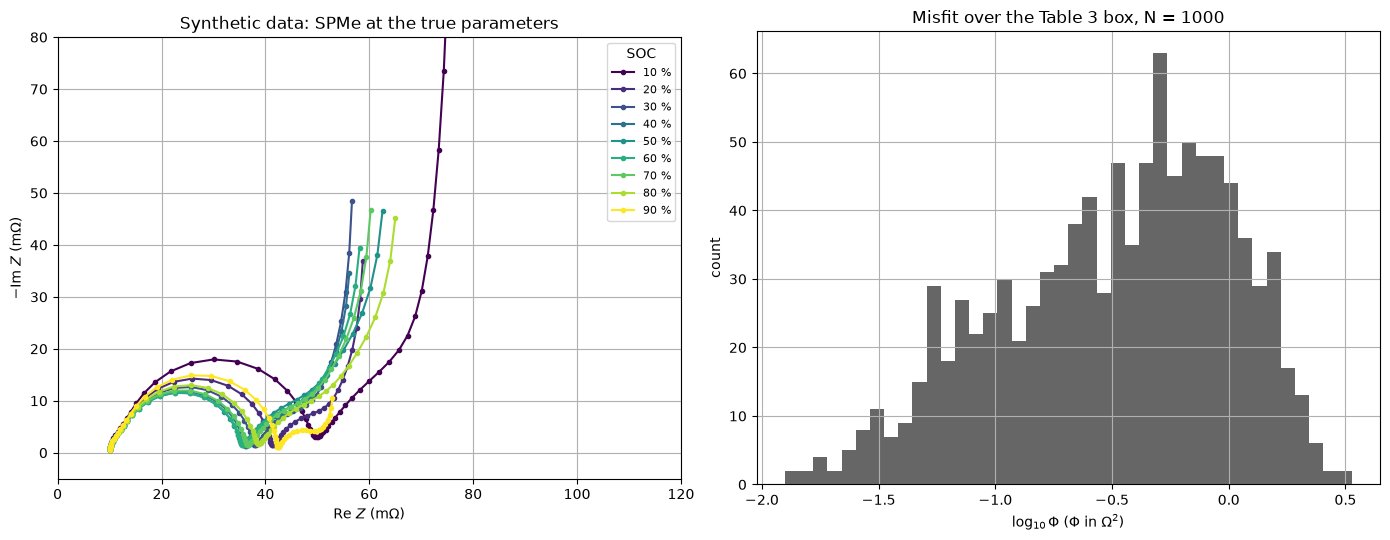

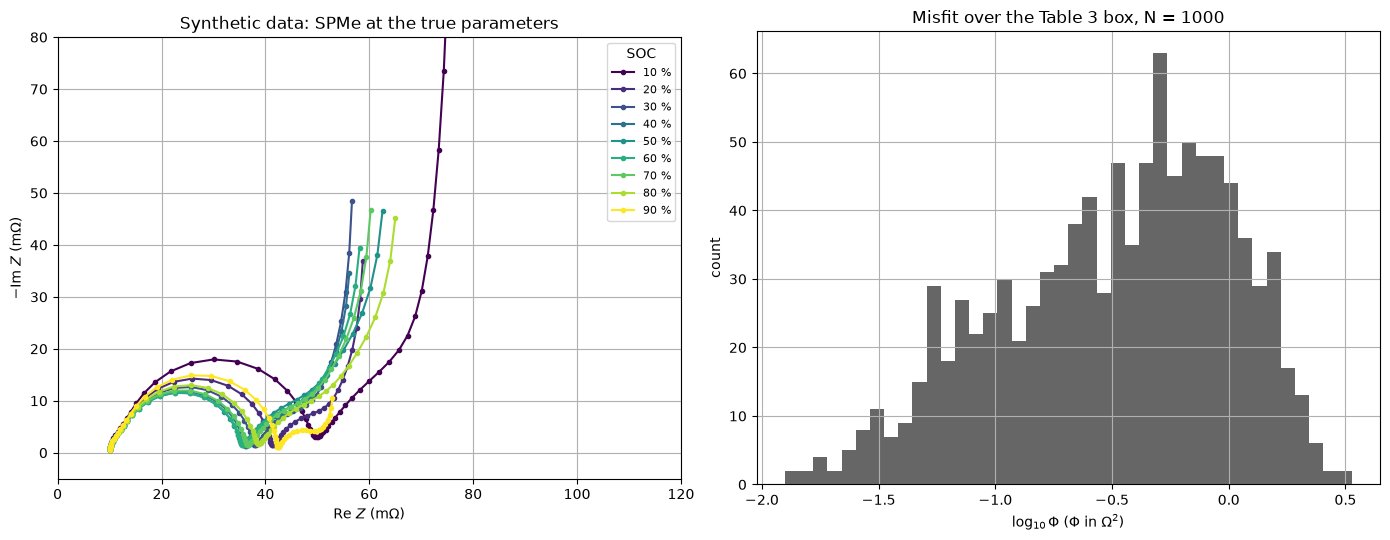

In [4]:
inside = np.all((X >= se.LOWER) & (X <= se.UPPER), axis=1)
print(f'{inside.sum()} of {len(X)} samples inside the Table 3 box; {len(np.unique(X, axis=0))} distinct rows')
print(f'smallest C+ = {X[:, 10].min():.2e} F, smallest C- = {X[:, 11].min():.2e} F; '
      f'samples with C+ or C- < 0.01 F: {np.sum((X[:, 10] < 0.01) | (X[:, 11] < 0.01))}')
print(f'true theta inside the box: {np.all((theta_true >= se.LOWER) & (theta_true <= se.UPPER))}; '
      f'all Phi > 0: {np.all(phi > 0)}')
print(f'Phi from {phi.min():.3e} to {phi.max():.3e} Ohm^2 (ratio {phi.max() / phi.min():.0f}, '
      f'{np.log10(phi.max() / phi.min()):.2f} decades); log10 Phi: 5/50/95 % = '
      f'{np.percentile(f, 5):.2f} / {np.median(f):.2f} / {np.percentile(f, 95):.2f}')
print(f'skewness of Phi {((phi - phi.mean())**3).mean() / phi.std()**3:.2f}, '
      f'of log10 Phi {((f - f.mean())**3).mean() / f.std()**3:.2f}')
print(f'sum of the per-SOC terms equals Phi to {np.max(np.abs(phim.sum(1) - phi) / phi):.1e} (relative)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
cmap = plt.get_cmap('viridis')
for m in range(9):
    z = Zr[:, 1 + 2 * m] + 1j * Zr[:, 2 + 2 * m]
    axes[0].plot(1e3 * z.real, -1e3 * z.imag, '.-', color=cmap(m / 8), label=f'{socs[m]} %')
axes[0].set_xlabel(r'Re $Z$ (m$\Omega$)'); axes[0].set_ylabel(r'$-$Im $Z$ (m$\Omega$)')
axes[0].set_xlim(0, 120); axes[0].set_ylim(-5, 80); axes[0].set_aspect('equal')
axes[0].legend(title='SOC', fontsize=8); axes[0].grid(True)
axes[0].set_title('Synthetic data: SPMe at the true parameters')
axes[1].hist(f, bins=40, color='0.4')
axes[1].set_xlabel(r'$\log_{10}\Phi$ ($\Phi$ in $\Omega^2$)'); axes[1].set_ylabel('count'); axes[1].grid(True)
axes[1].set_title(f'Misfit over the Table 3 box, N = {len(f)}')
fig.tight_layout()
fig

All 1000 samples lie in the box and are distinct; 16 have a double-layer capacitance below 0.01 F (smallest $C_- = 3.0\times10^{-4}$ F), kept, since the model is defined for any $C > 0$. The data spectra reproduce the shape of the paper's Fig. 7: a 10 mΩ offset, charge-transfer semicircles largest at 10 % SOC, and a diffusion tail that changes strongly with SOC. Over the box $\Phi$ runs from $1.26\times10^{-2}$ to $3.36$ Ω² (2.43 decades, a factor of 268); its skewness is 1.51, against −0.44 for $\log_{10}\Phi$, so the logarithm is the better-behaved QoI for regression and plots.

## Estimate the active subspace

We have exact gradients, so we use the gradient estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1N\sum_i\nabla f_i\nabla f_i^T$ in normalized coordinates. The inputs are all uniform, so each is scaled the same way, by its half-range: we pass physical samples and physical gradients with the space, and v1 normalizes them once. There are $N = 1000$ gradient samples for $m = 18$ inputs. The bootstrap uses 500 replicates. v1's eigenvalue-gap rule proposes the dimension; the next cells check it against the spectrum, the bootstrap subspace distances and the surrogate fits. Eigenvector signs: each of the first three is signed so that the mean gradient's component along it is positive (`ac.orient(by="mean_gradient")`), so that moving along $+\mathbf w_1$ increases the misfit on average.

In [5]:
space = ac.Uniform(se.LOWER, se.UPPER, names=se.NAMES)
sub = ac.active_subspace(space=space, grads=Gf, nboot=500, bootstrap_vectors=3, rng=SEED, qoi='log10 Phi')
sub = ac.orient(sub, by='mean_gradient', grads=Gf, columns=3)
lam = sub.eigenvalues
ci = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
ks, crit, khat = ac.dimension_criterion(sub, rule='evg')
print(f'eigenvalue-gap rule: n = {sub.n}')
for j in range(6):
    print(f'lambda_{j + 1} = {lam[j]:.4e}  (95% bootstrap {ci[0, j]:.4e} to {ci[1, j]:.4e})'
          + (f';  lambda_{j + 1}/lambda_{j + 2} = {lam[j] / lam[j + 1]:.2f}' if j < 5 else ''))
rb = sub.bootstrap_eigenvalues[:, 0] / sub.bootstrap_eigenvalues[:, 1]
print(f'lambda_1/lambda_2 bootstrap 95% range {np.percentile(rb, 2.5):.1f} to {np.percentile(rb, 97.5):.1f}')
print(f'share of trace(C): first {lam[0] / lam.sum():.3f}, first two {lam[:2].sum() / lam.sum():.3f}, '
      f'first three {lam[:3].sum() / lam.sum():.3f}; smallest eigenvalue {lam[-1]:.1e}')

eigenvalue-gap rule: n = 1
lambda_1 = 1.1475e+00  (95% bootstrap 1.0766e+00 to 1.2191e+00);  lambda_1/lambda_2 = 23.55
lambda_2 = 4.8732e-02  (95% bootstrap 3.5129e-02 to 6.6579e-02);  lambda_2/lambda_3 = 1.43
lambda_3 = 3.4008e-02  (95% bootstrap 2.6980e-02 to 4.2471e-02);  lambda_3/lambda_4 = 1.55
lambda_4 = 2.1890e-02  (95% bootstrap 1.5878e-02 to 2.5864e-02);  lambda_4/lambda_5 = 1.83
lambda_5 = 1.1989e-02  (95% bootstrap 9.6781e-03 to 1.5129e-02);  lambda_5/lambda_6 = 1.20
lambda_6 = 9.9920e-03  (95% bootstrap 7.6196e-03 to 1.1840e-02)
lambda_1/lambda_2 bootstrap 95% range 16.9 to 32.4
share of trace(C): first 0.892, first two 0.930, first three 0.957; smallest eigenvalue 1.4e-07


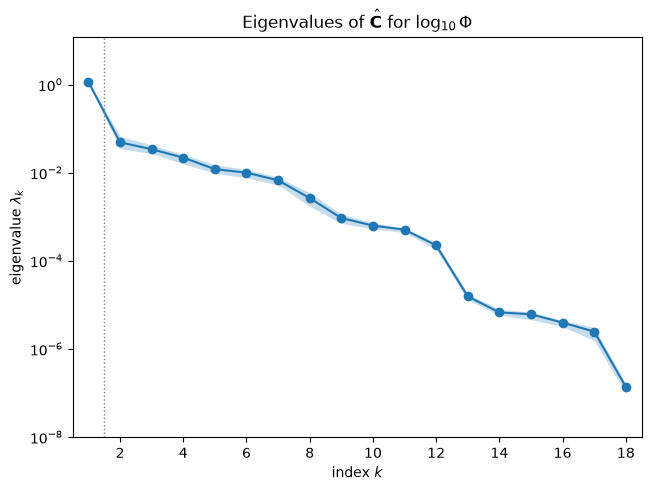

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub, k_max=18)
ax.set_title(r'Eigenvalues of $\hat{\mathbf{C}}$ for $\log_{10}\Phi$')
fig

The first eigenvalue is 23.6 times the second (bootstrap range of the ratio 16.9–32.4) and holds 0.892 of the trace; after it the spectrum decays slowly ($\lambda_2/\lambda_3 = 1.43$, $\lambda_3/\lambda_4 = 1.55$), so the gap rule picks $n = 1$. The eigenvalues after the first are close to each other, which is why v1 warns that the bootstrap replicates of $\mathbf w_2$ and $\mathbf w_3$ are poorly aligned: those two directions are not well determined, and we do not interpret them individually.

mean bootstrap subspace distance for n = 1..4: [0.013 0.205 0.207 0.134]


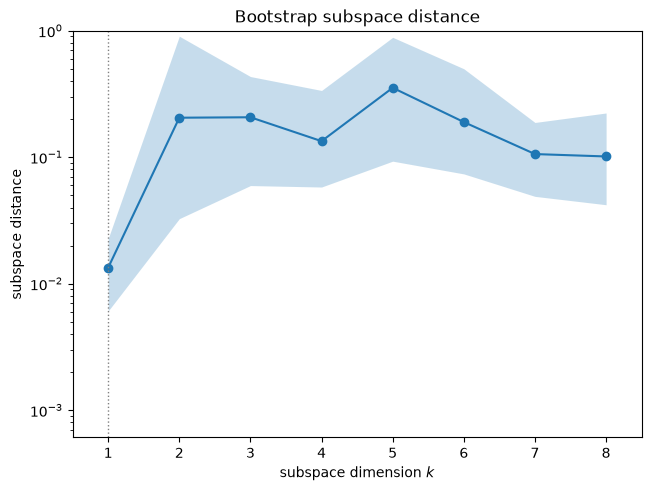

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub, k_max=8)
ax.set_title('Bootstrap subspace distance')
d = sub.bootstrap_distances
print('mean bootstrap subspace distance for n = 1..4:', np.round(d.mean(axis=0)[:4], 3))
fig

The mean bootstrap subspace distance is 0.013 for $n = 1$ and 0.205 for $n = 2$: the one-dimensional subspace is very stable, the two-dimensional one is not, consistent with the single large gap.

w1: R0 +0.754, tau_ct- +0.529, tau_ct+ +0.357, C- -0.084, C+ -0.059
w2: C- -0.980, tau_ct- -0.110, C+ -0.110, tau_ct+ -0.089, c-^0% +0.065
w3: C+ -0.621, tau_ct- -0.504, R0 +0.435, c-^0% +0.315, C- +0.169
true theta in normalized coordinates: R0 -0.60, tau_ct- +0.09, tau_ct+ -0.85


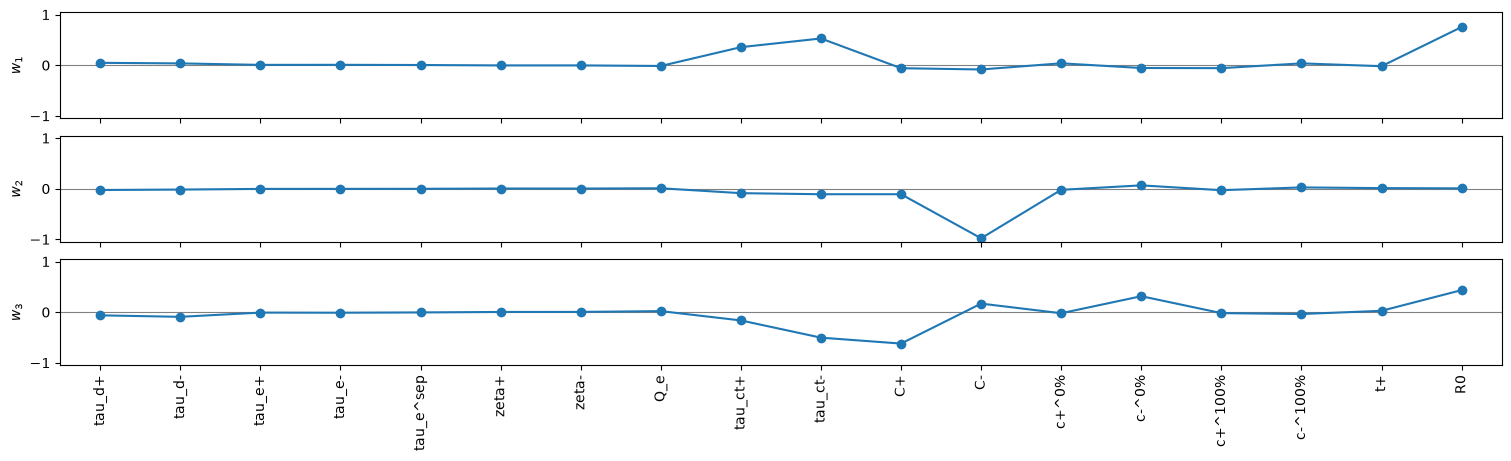

In [8]:
labels = [p[2] for p in se.PARAMETERS]
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1, 2], labels=labels, figsize=(15, 4.5))
W = sub.W
for k in range(3):
    o = np.argsort(-np.abs(W[:, k]))[:5]
    print(f'w{k + 1}: ' + ', '.join(f'{labels[i]} {W[i, k]:+.3f}' for i in o))
xt = space.to_normalized(theta_true[None])[0]
print('true theta in normalized coordinates: ' + ', '.join(f'{labels[i]} {xt[i]:+.2f}' for i in (17, 9, 8)))
fig

$\mathbf w_1$ is the series resistance ($+0.754$) and the negative and positive charge-transfer time scales ($+0.529$, $+0.357$), with small negative weights on the double-layer capacitances ($C_-$ −0.084, $C_+$ −0.059). These are the inputs that set where the spectra start on the real axis and how large the semicircles are (Section 5.4, Fig. 8), the largest features of the impedance. Moving along $+\mathbf w_1$ increases $R_0$ and $\tau^{ct}_\pm$, which raises the misfit on average (the sign rule). For $R_0$ and $\tau^{ct}_+$ this is because the true values sit low in their ranges (normalized −0.60 and −0.85), so most of the box lies above them; $\tau^{ct}_-$ is mid-range (+0.09). $\mathbf w_2$ is mostly $C_-$ (−0.980), but see the warning above.

corr(w1^T x, log10 Phi) = 0.913


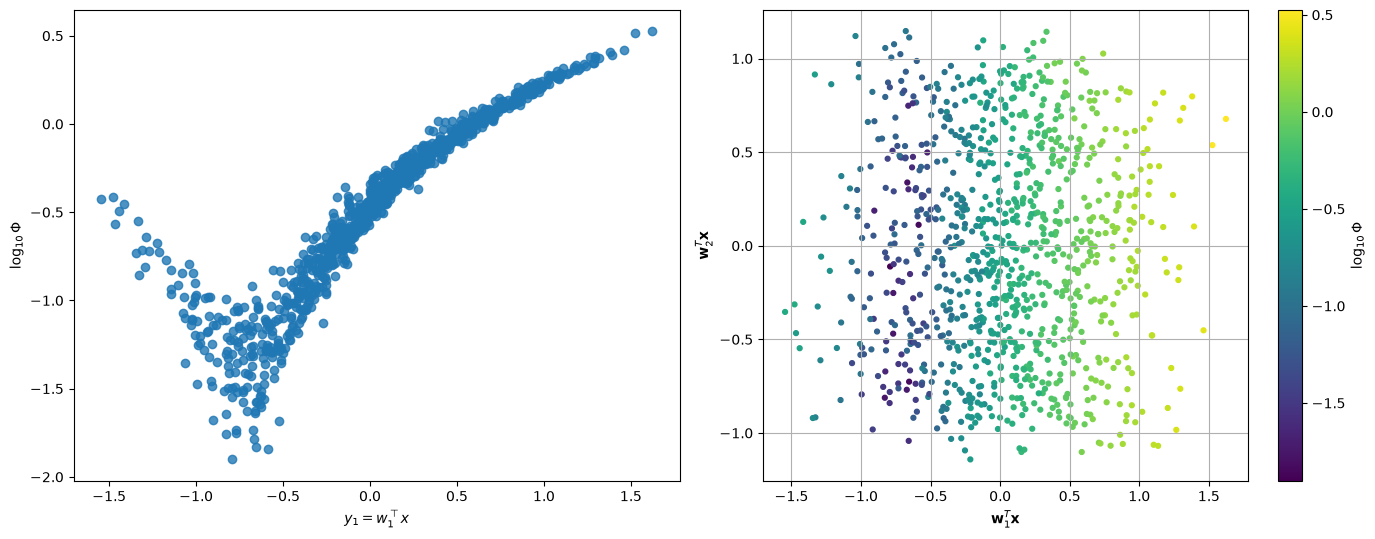

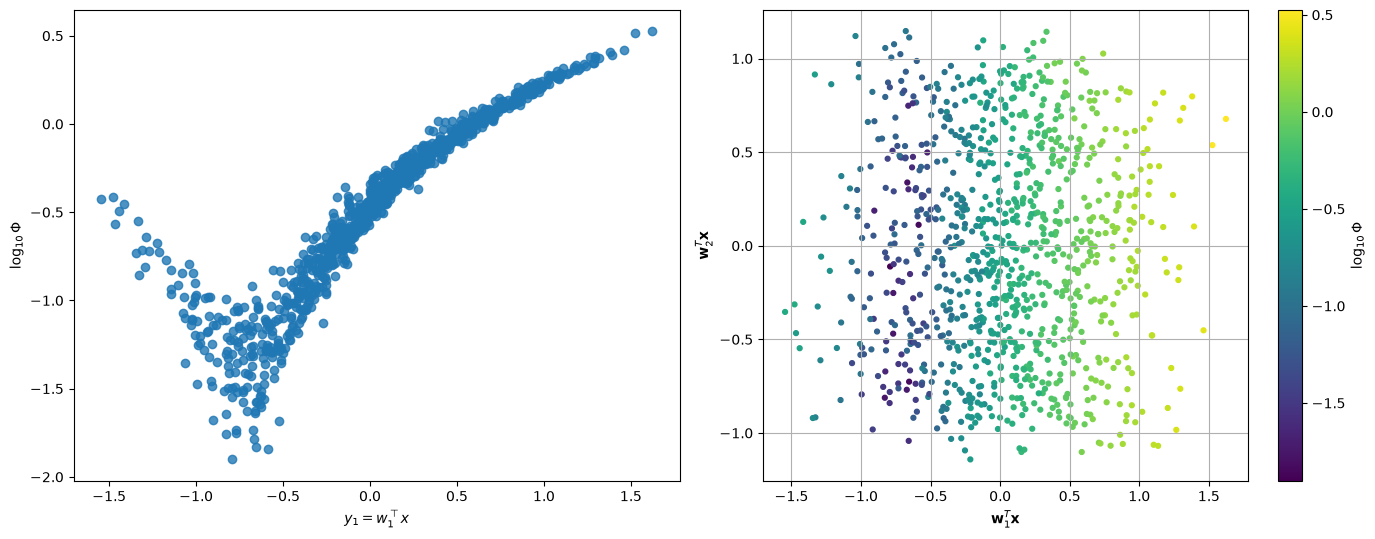

In [9]:
XN = space.to_normalized(X)
y = XN @ W[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label=r'$\log_{10}\Phi$', ax=axes[0])
sc = axes[1].scatter(y[:, 0], y[:, 1], c=f, s=12, cmap='viridis')
axes[1].set_xlabel(r'$\mathbf{w}_1^T\mathbf{x}$'); axes[1].set_ylabel(r'$\mathbf{w}_2^T\mathbf{x}$')
axes[1].grid(True); fig.colorbar(sc, ax=axes[1], label=r'$\log_{10}\Phi$')
print(f'corr(w1^T x, log10 Phi) = {np.corrcoef(y[:, 0], f)[0, 1]:.3f}')
fig.tight_layout()
fig

$\log_{10}\Phi$ follows a tight, curved trend in $\mathbf w_1^T\mathbf x$ (correlation 0.913), with its minimum near the left edge, where $R_0$ and $\tau^{ct}_\pm$ are small, as at the truth. The two-dimensional plot shows little additional structure along $\mathbf w_2$.

In [10]:
for n, deg in [(1, 2), (1, 3), (2, 2), (2, 3), (3, 2)]:
    s = ac.fit_surrogate(X=X, f=f, space=space, subspace=ac.with_dimension(sub, n), kind='poly', degree=deg)
    print(f'polynomial of degree {deg} in {n} active variable(s): LOO R^2 = {s.loo_r_squared:.3f}')

polynomial of degree 2 in 1 active variable(s): LOO R^2 = 0.835
polynomial of degree 3 in 1 active variable(s): LOO R^2 = 0.914
polynomial of degree 2 in 2 active variable(s): LOO R^2 = 0.835
polynomial of degree 3 in 2 active variable(s): LOO R^2 = 0.917
polynomial of degree 2 in 3 active variable(s): LOO R^2 = 0.846


A cubic in the single active variable has leave-one-out $R^2 = 0.914$ (quadratic 0.835); adding the second variable raises it only to 0.917, and a quadratic in three variables gives 0.846. One variable captures most of the misfit over the box; the remaining 9 % is spread over many small directions.

In [11]:
alpha = ac.activity_scores(sub, n=sub.n)
alpha3 = ac.activity_scores(sub, n=3)
alpha_all = ac.activity_scores(sub, n=18)       # = diag(C): mean squared normalized derivative
order = np.argsort(-alpha_all)
rows = ['| input | activity score, n = ' + str(sub.n) + ' | n = 3 | all 18 (diag C) | share of trace |',
        '|---|---|---|---|---|']
for i in order:
    rows.append(f'| {labels[i]} | {alpha[i]:.2e} | {alpha3[i]:.2e} | {alpha_all[i]:.2e} | '
                f'{alpha_all[i] / alpha_all.sum():.4f} |')
display(Markdown('\n'.join(rows)))
print(f'three inputs carry {np.sort(alpha_all)[::-1][:3].sum() / alpha_all.sum():.3f} of trace(C); '
      f'five carry {np.sort(alpha_all)[::-1][:5].sum() / alpha_all.sum():.3f}')

| input | activity score, n = 1 | n = 3 | all 18 (diag C) | share of trace |
|---|---|---|---|---|
| R0 | 6.53e-01 | 6.59e-01 | 6.64e-01 | 0.5165 |
| tau_ct- | 3.21e-01 | 3.30e-01 | 3.35e-01 | 0.2605 |
| tau_ct+ | 1.46e-01 | 1.47e-01 | 1.54e-01 | 0.1196 |
| C- | 8.12e-03 | 5.59e-02 | 5.59e-02 | 0.0435 |
| C+ | 3.98e-03 | 1.77e-02 | 3.03e-02 | 0.0236 |
| c-^0% | 3.47e-03 | 7.05e-03 | 1.73e-02 | 0.0135 |
| c+^100% | 3.82e-03 | 3.88e-03 | 1.37e-02 | 0.0107 |
| tau_d- | 1.48e-03 | 1.79e-03 | 5.36e-03 | 0.0042 |
| tau_d+ | 2.57e-03 | 2.74e-03 | 4.03e-03 | 0.0031 |
| c-^100% | 1.53e-03 | 1.61e-03 | 2.40e-03 | 0.0019 |
| c+^0% | 1.64e-03 | 1.68e-03 | 2.37e-03 | 0.0018 |
| t+ | 4.26e-04 | 4.54e-04 | 6.37e-04 | 0.0005 |
| Q_e | 2.63e-04 | 2.80e-04 | 4.66e-04 | 0.0004 |
| tau_e- | 7.26e-05 | 7.78e-05 | 1.37e-04 | 0.0001 |
| tau_e+ | 5.66e-05 | 6.04e-05 | 1.05e-04 | 0.0001 |
| tau_e^sep | 2.13e-05 | 2.28e-05 | 3.77e-05 | 0.0000 |
| zeta- | 1.52e-05 | 1.62e-05 | 2.56e-05 | 0.0000 |
| zeta+ | 1.64e-05 | 1.73e-05 | 2.48e-05 | 0.0000 |

three inputs carry 0.897 of trace(C); five carry 0.964


Three inputs, $R_0$ (0.517 of the trace), $\tau^{ct}_-$ (0.261) and $\tau^{ct}_+$ (0.120), carry 0.897 of $\mathrm{trace}(\mathbf C)$, and with $C_-$ and $C_+$ five carry 0.964. The electrolyte and separator parameters ($\tau^e_\pm$, $\tau^{sep}_e$, $\zeta_\pm$, $Q_e$, $t^+$) each have at most 0.0005 of the trace. Apart from $t^+$, which Table 3 estimates within 2 %, these are the groups the paper reports as poorly estimated (Table 3: $\tau^e_+$, $\tau^{sep}_e$, $\zeta_\pm$ and $Q_e$ ended at a bound of the box) and as having "small features in the impedance" (Section 6.1). Consistent with Section 5.4, $\tau^{ct}_-$ matters more than $\tau^{ct}_+$ and $\tau^{sep}_e$ has almost no effect.

### Why the logarithm

The same analysis on $\Phi$ itself (gradients $\nabla\Phi$) for comparison:

In [12]:
sub_raw = ac.active_subspace(space=space, grads=G)
lr = sub_raw.eigenvalues
print('Phi: lambda_j/lambda_(j+1), j = 1..4:', np.round(lr[:4] / lr[1:5], 2))
print(f'|w1(Phi) . w1(log10 Phi)| = {abs(sub_raw.W[:, 0] @ W[:, 0]):.3f}')
s = ac.fit_surrogate(X=X, f=phi, space=space, subspace=ac.with_dimension(sub_raw, 1), kind='poly', degree=3)
print(f'Phi: cubic in w1^T x, LOO R^2 = {s.loo_r_squared:.3f}')

Phi: lambda_j/lambda_(j+1), j = 1..4: [12.25  3.96  4.8   1.79]
|w1(Phi) . w1(log10 Phi)| = 0.996
Phi: cubic in w1^T x, LOO R^2 = 0.982


For $\Phi$ itself the first gap is smaller ($\lambda_1/\lambda_2 = 12.25$) but the direction is the same ($|\mathbf w_1\cdot\mathbf w_1| = 0.996$), and a cubic in it fits $\Phi$ with LOO $R^2 = 0.982$. Over this box $\Phi$ spans 2.43 decades, so the logarithm sharpens the gap and symmetrizes the QoI rather than changing the answer.

### Uniform or log-uniform time scales

The uniform density puts most samples at large time scales. To see how much the result depends on that choice, we reweight the same 1000 samples to a density that is log-uniform on $\tau^d_\pm$ and $\tau^{ct}_\pm$ (uniform on the others). In coordinates $u = \ln\tau$ for these four inputs the target is uniform on the box, the gradients follow by the chain rule ($\partial f/\partial u = \tau\,\partial f/\partial\tau$), and the importance weights are $\omega_i \propto \prod_j 1/\tau_{ij}$ over the four inputs, normalized to sum to 1 (passed as `quad_weights`). We also show the log coordinates with the uniform weights, which changes only the scaling of the four inputs. The weights are very uneven, so the reweighted numbers are indicative only; v1 warns that its bootstrap is not designed for non-uniform weights.

In [13]:
L = [0, 1, 8, 9]                                         # tau_d+, tau_d-, tau_ct+, tau_ct-
yt = space.to_normalized(theta_true[None])[0] @ W[:, 0]
print(f'fraction of samples with tau_ct+ above its true value: {np.mean(X[:, 8] > theta_true[8]):.2f}; '
      f'with w1^T x below its value at the truth: {np.mean(XN @ W[:, 0] < yt):.2f}')
lo, hi = se.LOWER.copy(), se.UPPER.copy()
lo[L], hi[L] = np.log(lo[L]), np.log(hi[L])
space_log = ac.Uniform(lo, hi, names=se.NAMES)           # ln(tau) for the four time scales
XL = X.copy(); XL[:, L] = np.log(X[:, L])
GL = Gf.copy(); GL[:, L] = Gf[:, L] * X[:, L]           # df/d ln(tau) = tau df/dtau
wq = 1 / np.prod(X[:, L], axis=1); wq /= wq.sum()       # log-uniform target over uniform design
print(f'effective sample size of the weights: {1 / np.sum(wq**2):.0f} of {len(X)}; largest weight {wq.max():.3f}')
print(f'uniform (as above): lambda_1/lambda_2 = {lam[0] / lam[1]:.2f} (bootstrap {np.percentile(rb, 2.5):.1f} to '
      f'{np.percentile(rb, 97.5):.1f}), lambda_1 share {lam[0] / lam.sum():.2f}')
for nm, kw in [('log coordinates, uniform weights', {}), ('log-uniform (reweighted)', dict(quad_weights=wq))]:
    s = ac.active_subspace(space=space_log, grads=GL, nboot=500, rng=SEED, **kw)
    l = s.eigenvalues
    r = s.bootstrap_eigenvalues[:, 0] / s.bootstrap_eigenvalues[:, 1]
    w1 = s.W[:, 0] * np.sign(s.W[:, 0] @ W[:, 0])
    o = np.argsort(-np.abs(w1))[:4]
    print(f'{nm}: n = {s.n}, lambda_1/lambda_2 = {l[0] / l[1]:.1f} (bootstrap {np.percentile(r, 2.5):.1f} to '
          f'{np.percentile(r, 97.5):.1f}), lambda_1 share {l[0] / l.sum():.2f}; w1: '
          + ', '.join(f'{labels[i]} {w1[i]:+.2f}' for i in o) + f'; componentwise cosine with w1 above {abs(w1 @ W[:, 0]):.3f}')

fraction of samples with tau_ct+ above its true value: 0.93; with w1^T x below its value at the truth: 0.09
effective sample size of the weights: 41 of 1000; largest weight 0.137
uniform (as above): lambda_1/lambda_2 = 23.55 (bootstrap 16.9 to 32.4), lambda_1 share 0.89


log coordinates, uniform weights: n = 1, lambda_1/lambda_2 = 9.1 (bootstrap 8.2 to 10.3), lambda_1 share 0.83; w1: tau_ct- +0.74, R0 +0.47, tau_ct+ +0.46, C- -0.06; componentwise cosine with w1 above 0.932


log-uniform (reweighted): n = 1, lambda_1/lambda_2 = 5.2 (bootstrap 4.5 to 6.1), lambda_1 share 0.74; w1: R0 +0.67, tau_ct- +0.60, tau_ct+ +0.42, C- -0.06; componentwise cosine with w1 above 0.990


Under the uniform density 93 % of the samples have $\tau^{ct}_+$ above its true value, and only 9 % lie below the truth along $\mathbf w_1$: the box sample sees mostly the large-time-scale side of the minimum. Reweighting to log-uniform time scales (effective sample size 41 of 1000, largest weight 0.137, so the numbers are indicative only) lowers $\lambda_1/\lambda_2$ from 23.55 to 5.2 (bootstrap 4.5–6.1) and the share of $\lambda_1$ from 0.89 to 0.74; the log coordinates alone, with uniform weights, give 9.1. The direction does not change: after reweighting $\mathbf w_1$ is $R_0$ +0.67, $\tau^{ct}_-$ +0.60, $\tau^{ct}_+$ +0.42 (componentwise cosine 0.990 with $\mathbf w_1$ above), and the gap rule still picks $n = 1$. So the one-dimensional structure and its inputs are robust to the choice of measure; the size of the gap is not.

## One SOC versus nine

The paper concludes that the parameters must be fitted to spectra at several SOCs at once (abstract, Sections 5.3–5.4), and that $\tau^d_-$ cannot be identified at SOCs where the graphite OCP is flat (Fig. 12; "At 50% SOC $\tau^d_-$ seems not to affect the impedance"). We repeat the analysis for each per-SOC misfit $\log_{10}\Phi_m$, using the stored per-SOC gradients.

In [14]:
rows = ['| SOC | λ1/λ2 | λ2/λ3 | gap-rule n | share of trace(C): τd− | τd+ | c−0% | c−100% | |w1(SOC)·w1(all)| |',
        '|---|---|---|---|---|---|---|---|---|']
share = {}
for m in range(9):
    s = ac.active_subspace(space=space, grads=Gfm[:, m])
    l = s.eigenvalues
    a = ac.activity_scores(s, n=18)
    share[socs[m]] = a / a.sum()
    rows.append(f'| {socs[m]} % | {l[0] / l[1]:.1f} | {l[1] / l[2]:.1f} | {s.n} | {a[1] / a.sum():.1e} | '
                f'{a[0] / a.sum():.1e} | {a[13] / a.sum():.1e} | {a[15] / a.sum():.1e} | {abs(s.W[:, 0] @ W[:, 0]):.3f} |')
a = alpha_all / alpha_all.sum()
rows.append(f'| all 9 | {lam[0] / lam[1]:.1f} | {lam[1] / lam[2]:.1f} | {sub.n} | {a[1]:.1e} | {a[0]:.1e} | '
            f'{a[13]:.1e} | {a[15]:.1e} | 1 |')
display(Markdown('\n'.join(rows)))
print('share of trace(C) of tau_d-: ' + ', '.join(f'{k} % {v[1]:.1e}' for k, v in share.items()))
print(f'log10 of the ratio of tau_d- shares, 10 % SOC over 50 % SOC: {np.log10(share[10][1] / share[50][1]):.1f}')

| SOC | λ1/λ2 | λ2/λ3 | gap-rule n | share of trace(C): τd− | τd+ | c−0% | c−100% | |w1(SOC)·w1(all)| |
|---|---|---|---|---|---|---|---|---|
| 10 % | 7.2 | 2.5 | 1 | 6.6e-02 | 1.9e-03 | 1.3e-01 | 1.7e-03 | 0.961 |
| 20 % | 25.9 | 1.3 | 1 | 1.2e-03 | 1.7e-03 | 5.8e-03 | 8.3e-04 | 0.999 |
| 30 % | 29.3 | 1.3 | 1 | 2.1e-03 | 2.2e-03 | 4.6e-03 | 4.5e-04 | 0.998 |
| 40 % | 35.8 | 1.2 | 1 | 6.9e-05 | 3.9e-03 | 1.9e-03 | 4.7e-04 | 0.997 |
| 50 % | 29.2 | 1.3 | 1 | 8.7e-07 | 8.3e-03 | 9.3e-04 | 7.5e-04 | 0.996 |
| 60 % | 31.6 | 1.3 | 1 | 3.4e-04 | 5.4e-03 | 8.3e-04 | 4.3e-03 | 0.996 |
| 70 % | 31.1 | 1.3 | 1 | 7.8e-04 | 7.0e-03 | 2.3e-03 | 3.2e-03 | 0.998 |
| 80 % | 22.5 | 1.4 | 1 | 5.0e-07 | 6.3e-03 | 6.8e-04 | 3.3e-03 | 0.998 |
| 90 % | 8.3 | 2.5 | 1 | 3.0e-11 | 5.8e-03 | 7.0e-04 | 7.3e-03 | 0.993 |
| all 9 | 23.5 | 1.4 | 1 | 4.2e-03 | 3.1e-03 | 1.3e-02 | 1.9e-03 | 1 |

share of trace(C) of tau_d-: 10 % 6.6e-02, 20 % 1.2e-03, 30 % 2.1e-03, 40 % 6.9e-05, 50 % 8.7e-07, 60 % 3.4e-04, 70 % 7.8e-04, 80 % 5.0e-07, 90 % 3.0e-11
log10 of the ratio of tau_d- shares, 10 % SOC over 50 % SOC: 4.9


Every single-SOC misfit also has $n = 1$ ($\lambda_1/\lambda_2$ from 7.2 at 10 % to 35.8 at 40 %), and its $\mathbf w_1$ agrees with the nine-SOC one to at least 0.961, so the dominant global structure does not depend on the SOC. What changes with SOC is the weight of the small inputs. The share of $\tau^d_-$ is $6.6\times10^{-2}$ at 10 % SOC but $8.7\times10^{-7}$ at 50 % (4.9 decades smaller) and $3.0\times10^{-11}$ at 90 %, as the paper finds ("At 50% SOC $\tau^d_-$ seems not to affect the impedance"; Fig. 12, where the graphite OCP is flat), and the share of $c_-^{0\%}$ falls from $1.3\times10^{-1}$ at 10 % to below $6\times10^{-3}$ elsewhere. Only the low-SOC spectrum informs these inputs, which supports the paper's advice to fit several SOCs together.

## Local identifiability at the true parameters

The paper measures identifiability by the spread of the best fits over ten particle-swarm restarts (Table 3, $\sigma_{\hat\theta}/\hat\theta$) and notes that the Fisher information matrix would be a better measure. Near the minimum $\Phi$ is quadratic, $\Phi(\boldsymbol\theta_{true}+\delta) \approx \delta^T\mathbf H\delta$ with the Gauss–Newton matrix $\mathbf H = \mathrm{Re}(\mathbf J_Z^H\mathbf J_Z)$ built from the impedance sensitivities $\mathbf J_Z = \partial Z/\partial\boldsymbol\theta$ (540 × 18, in `impedance_jacobian.csv`); $2\mathbf H/\sigma^2$ is the Fisher information for i.i.d. complex Gaussian noise of variance $\sigma^2$ at each of the 540 data points, so $(\sigma^2/2)\mathbf H^{-1}$ is the Cramér–Rao bound on the covariance of an unbiased estimate. The paper's data are noise-free, so $\sigma$ is not defined here; the ranking of the inputs by the local standard deviations $\propto\sqrt{(\mathbf H^{-1})_{ii}}$ does not depend on it. We use this local analysis **as a ranking only**: $\Phi$ is far from quadratic at the distances such standard deviations would imply for the poorly identified groups (checked below), so their absolute values are not meaningful and are not quoted. The global active subspace above describes $\Phi$ over the whole search box, and $\mathbf H$ only its neighbourhood of the truth, so the two need not agree; we compare their rankings and their subspaces. We work in the same normalized coordinates (half-ranges of Table 3). To compare rankings with one orientation (large = poorly identified), we use the local standard deviation and the reciprocal $1/s_i$ of the global share $s_i$ of $\mathrm{trace}(\mathbf C)$.

In [15]:
half = (se.UPPER - se.LOWER) / 2
Jc = (JZ[:, 2:20] + 1j * JZ[:, 20:38]) * half          # dZ/dx, normalized coordinates
H = np.real(Jc.conj().T @ Jc)
hev, hW = np.linalg.eigh(H)
hev, hW = hev[::-1], hW[:, ::-1]
print('eigenvalues of H (normalized coords), largest/smallest:', f'{hev[0]:.3e} / {hev[-1]:.3e}',
      f'(condition number {hev[0] / hev[-1]:.1e})')
print('lambda_j(H)/lambda_(j+1)(H), j = 1..6:', np.round(hev[:6] / hev[1:7], 2))
v1 = hW[:, 0] * np.sign(hW[:, 0] @ W[:, 0])
print(f'leading eigenvector of H: ' + ', '.join(f'{labels[i]} {v1[i]:+.3f}' for i in np.argsort(-np.abs(v1))[:3])
      + f'; |w1(C) . v1(H)| = {abs(v1 @ W[:, 0]):.3f} ({np.degrees(np.arccos(abs(v1 @ W[:, 0]))):.1f} deg)')
print('smallest-eigenvalue direction of H: ' + ', '.join(
    f'{labels[i]} {hW[i, -1]:+.3f}' for i in np.argsort(-np.abs(hW[:, -1]))[:4]))
# local (Cramer-Rao) standard deviations, up to the common factor sigma / sqrt(2): Cov = (sigma^2 / 2) H^-1
# (normalized coordinates). Used as a ranking only; the scale is not meaningful (see the text).
sd_n = np.sqrt(np.diag(np.linalg.inv(H)))                         # in half-ranges, per unit sigma/sqrt(2)
sd_rel = sd_n * half / np.abs(theta_true)
sd_rank = np.argsort(np.argsort(sd_rel)) + 1                      # 1 = best identified locally
# Table 3, p. 12: relative standard deviation of the ten impedance fits, sigma/theta-hat [%]
paper_sd = np.array([0.38, 0.93, 0.011, 20.9, 0.61, 0.0019, 41.9, 8.20, 26.5, 5.07, 13.9, 8.68,
                     0.10, 11.8, 0.22, 0.31, 9.16, 1.22])
paper_hat = np.array([6682, 1020, 200.0, 403.5, 200.0, 0.500, 1.500, 500.0, 5158, 27746, 0.6178, 0.6953,
                      0.8548, 0.02634, 0.2642, 0.9092, 0.2647, 0.0101])
paper_err = np.abs(paper_hat - theta_true) / theta_true
at_bound = np.isclose(paper_hat, se.LOWER) | np.isclose(paper_hat, se.UPPER)
rows = ['| input | true θ | Table 3 θ̂ | rel. error of θ̂ | Table 3 σ/θ̂ (%) | local rank (sd/θ; 1 = best identified) | global share of trace(C) |',
        '|---|---|---|---|---|---|---|']
for i in np.argsort(sd_rel):
    rows.append(f'| {labels[i]} | {theta_true[i]:.4g} | {paper_hat[i]:.4g}{" (bound)" if at_bound[i] else ""} | '
                f'{paper_err[i]:.3f} | {paper_sd[i]:g} | {sd_rank[i]} | {a[i]:.4f} |')
display(Markdown('\n'.join(rows)))
inv_share = 1 / a                                       # large = small global share
for nm, q in [('Table 3 sigma/theta-hat', paper_sd), ('|theta-hat - theta|/theta', paper_err),
              ('|theta-hat - theta|/half-range', np.abs(paper_hat - theta_true) / half)]:
    print(f'Spearman rank correlation with {nm}: local sd {spearmanr(sd_rel, q)[0]:+.2f}, '
          f'1/global share {spearmanr(inv_share, q)[0]:+.2f}')
print(f'Spearman(local sd, 1/global share) = {spearmanr(sd_rel, inv_share)[0]:+.2f}')
poor = np.zeros(18, bool); poor[[2, 3, 4, 5, 6, 7, 16]] = True     # tau_e+-, tau_e^sep, zeta+-, Q_e, t+
print(f'group indicator (7 electrolyte groups and t+ vs 11 others) vs best-fit errors: '
      f'Spearman {spearmanr(poor, paper_err)[0]:+.2f}; local sd within the 11: '
      f'{spearmanr(sd_rel[~poor], paper_err[~poor])[0]:+.2f}, within the 7: {spearmanr(sd_rel[poor], paper_err[poor])[0]:+.2f}')
print('Table 3 estimates on a bound of the box: ' + ', '.join(labels[i] for i in np.where(at_bound)[0])
      + '; local ranks of the 7 poorly identified groups: ' + ', '.join(f'{labels[i]} {sd_rank[i]}' for i in np.flatnonzero(poor)))
# subspaces: weakest directions of C and H vs the coordinate subspace of the 7 poorly identified groups
E7, E6 = np.eye(18)[:, poor], np.eye(18)[:, [2, 3, 4, 5, 6, 7]]
ang = lambda A, B: np.degrees(subspace_angles(A, B))
print(f'largest principal angle, 6 weakest eigenvectors of C vs the 7 coordinates: {ang(W[:, -6:], E7).max():.1f} deg '
      f'(vs the 6 without t+: {ang(W[:, -6:], E6).max():.1f} deg; 7 weakest vs the 7: {ang(W[:, -7:], E7).max():.1f} deg)')
print(f'largest principal angle, 5 weakest eigenvectors of H vs the 7 coordinates: {ang(hW[:, -5:], E7).max():.1f} deg')
print('principal angles between the 6 weakest directions of C and of H (deg):', np.round(np.sort(ang(W[:, -6:], hW[:, -6:])), 1))
print(f"H's 6th-weakest eigenvector: C+ component {abs(hW[10, -6]):.3f}")
# how far Phi is quadratic along H's weakest direction: cases 2-5 of check_parameters.csv
vmin = hW[:, -1] * np.sign(hW[np.argmax(np.abs(hW[:, -1])), -1])
for c, t in zip(range(2, 6), (1e-3, -1e-3, 1e-2, -1e-2)):
    dev = np.max(np.abs(Pc[c, 1:] - (theta_true + t * half * vmin)) / half)
    ph = np.sum(np.abs(Zc[c] - Zref) ** 2)
    print(f'truth {t:+.0e} v_min(H): Phi / t^2 = {ph / t**2:.2e} = {ph / t**2 / hev[-1]:.1f} x lambda_min(H) '
          f'(point matches to {dev:.0e})')

eigenvalues of H (normalized coords), largest/smallest: 5.629e-01 / 1.821e-12 (condition number 3.1e+11)
lambda_j(H)/lambda_(j+1)(H), j = 1..6: [8.88 2.57 1.68 3.37 1.81 1.62]
leading eigenvector of H: R0 +0.746, tau_ct- +0.534, tau_ct+ +0.382; |w1(C) . v1(H)| = 0.995 (5.9 deg)
smallest-eigenvalue direction of H: Q_e -0.807, tau_e- -0.364, zeta+ +0.294, zeta- +0.251


| input | true θ | Table 3 θ̂ | rel. error of θ̂ | Table 3 σ/θ̂ (%) | local rank (sd/θ; 1 = best identified) | global share of trace(C) |
|---|---|---|---|---|---|---|
| c-^100% | 0.9106 | 0.9092 | 0.002 | 0.31 | 1 | 0.0019 |
| c+^0% | 0.854 | 0.8548 | 0.001 | 0.1 | 2 | 0.0018 |
| c+^100% | 0.2638 | 0.2642 | 0.001 | 0.22 | 3 | 0.0107 |
| tau_ct- | 2.759e+04 | 2.775e+04 | 0.006 | 5.07 | 4 | 0.2605 |
| R0 | 0.01 | 0.0101 | 0.010 | 1.22 | 5 | 0.5165 |
| C- | 0.6719 | 0.6953 | 0.035 | 8.68 | 6 | 0.0435 |
| tau_d+ | 6812 | 6682 | 0.019 | 0.38 | 7 | 0.0031 |
| tau_d- | 1041 | 1020 | 0.020 | 0.93 | 8 | 0.0042 |
| c-^0% | 0.02635 | 0.02634 | 0.000 | 11.8 | 9 | 0.0135 |
| tau_ct+ | 4657 | 5158 | 0.108 | 26.5 | 10 | 0.1196 |
| C+ | 0.5935 | 0.6178 | 0.041 | 13.9 | 11 | 0.0236 |
| t+ | 0.2594 | 0.2647 | 0.020 | 9.16 | 12 | 0.0005 |
| tau_e^sep | 246.2 | 200 (bound) | 0.188 | 0.61 | 13 | 0.0000 |
| zeta+ | 0.7128 | 0.5 (bound) | 0.299 | 0.0019 | 14 | 0.0000 |
| tau_e+ | 409.1 | 200 (bound) | 0.511 | 0.011 | 15 | 0.0001 |
| tau_e- | 634.5 | 403.5 | 0.364 | 20.9 | 16 | 0.0001 |
| zeta- | 0.5319 | 1.5 (bound) | 1.820 | 41.9 | 17 | 0.0000 |
| Q_e | 804.8 | 500 (bound) | 0.379 | 8.2 | 18 | 0.0004 |

Spearman rank correlation with Table 3 sigma/theta-hat: local sd +0.36, 1/global share -0.25
Spearman rank correlation with |theta-hat - theta|/theta: local sd +0.88, 1/global share +0.59
Spearman rank correlation with |theta-hat - theta|/half-range: local sd +0.77, 1/global share +0.74
Spearman(local sd, 1/global share) = +0.63
group indicator (7 electrolyte groups and t+ vs 11 others) vs best-fit errors: Spearman +0.78; local sd within the 11: +0.61, within the 7: +0.82
Table 3 estimates on a bound of the box: tau_e+, tau_e^sep, zeta+, zeta-, Q_e; local ranks of the 7 poorly identified groups: tau_e+ 15, tau_e- 16, tau_e^sep 13, zeta+ 14, zeta- 17, Q_e 18, t+ 12
largest principal angle, 6 weakest eigenvectors of C vs the 7 coordinates: 3.8 deg (vs the 6 without t+: 53.3 deg; 7 weakest vs the 7: 25.8 deg)
largest principal angle, 5 weakest eigenvectors of H vs the 7 coordinates: 0.4 deg
principal angles between the 6 weakest directions of C and of H (deg): [ 0.2  0.8  1.   2.7 17.  89

The Gauss–Newton matrix at the truth is extremely ill-conditioned (condition number $3.1\times10^{11}$). Its leading eigenvector is the global $\mathbf w_1$ ($R_0$ +0.746, $\tau^{ct}_-$ +0.534, $\tau^{ct}_+$ +0.382; $|\mathbf w_1\cdot\mathbf v_1(\mathbf H)| = 0.995$, 5.9°): the globally active direction is also the best-identified direction at the truth. Its weakest direction is a combination of the electrolyte parameters ($Q_e$ −0.807, $\tau^e_-$ −0.364, $\zeta_+$ +0.294, $\zeta_-$ +0.251), and the weak subspaces of the two matrices nearly coincide: the 6 weakest eigenvectors of $\mathbf C$ lie within 3.8° of the coordinate subspace of the seven groups $\tau^e_\pm$, $\tau^{sep}_e$, $\zeta_\pm$, $Q_e$, $t^+$ (53.3° from the six without $t^+$), the 5 weakest of $\mathbf H$ within 0.4° of it, and the 6 weakest directions of $\mathbf C$ and $\mathbf H$ share five directions (principal angles 0.2–17°), the sixth of $\mathbf H$ being $C_+$ alone (component 0.997). With one orientation for both (large = poorly identified), the rankings agree: Spearman(local sd, 1/global share) = +0.63.

By the local standard deviation relative to the true value, the seven groups rank 12th to 18th, behind the other eleven (table). Only this ranking is used. Along $\mathbf H$'s weakest direction $\Phi/t^2$ is 2.1 $\lambda_{min}(\mathbf H)$ at $t = 10^{-3}$ and 112 $\lambda_{min}(\mathbf H)$ at $t = 10^{-2}$ (normalized coordinates), so $\Phi$ is quadratic only within about $10^{-3}$ half-ranges of the truth, while a Cramér–Rao bound at any plausible noise level puts the weak groups' standard deviations many orders of magnitude further out; the absolute values of the bound therefore carry no information here. As rankings, the local standard deviations follow the relative errors of the paper's best fit (Table 3) more closely than the global shares (Spearman +0.88 against +0.59; +0.77 against +0.74 for errors relative to the half-range). The +0.88 needs its caveats: the group indicator alone (7 against 11) gives +0.78, and within the groups the correlation is +0.61 (the 11 well identified) and +0.82 (the 7 poorly identified); five of the seven poorly identified estimates sit on a bound of the box ($\tau^e_+$, $\tau^{sep}_e$, $\zeta_\pm$, $Q_e$), so their errors are set by the box and the optimiser rather than by the curvature; the best fit has fitting errors near 1 % (next section), so the swarm did not reach the noise-free optimum $\Phi = 0$; and $t^+$, which ranks among the poorly identified both locally and globally, was estimated within 2 %. The paper's practical non-identifiability is therefore consistent with this low-rank structure, global and local, rather than proven by it. The restart spread $\sigma_{\hat\theta}/\hat\theta$ is ranked only weakly by the local sd (+0.36) and not by the global shares (−0.25): that spread also reflects the optimiser (several electrolyte estimates sat at a bound with small spread, e.g. $\tau^e_+$ 0.011 %).

### The paper's best fit (Table 3)

Table 3 also lists the fitting errors of the best of the ten particle-swarm fits, $\mathrm{FE}_m = \frac{100}{K}\sum_k |Z_m(\omega_k) - Z_m(\omega_k,\hat{\boldsymbol\theta})|/|Z_m(\omega_k)|$ (Eq. 17). They need only the printed $\hat{\boldsymbol\theta}$, at which the model was run once (case 0 of `check_parameters.csv`). The printed values are rounded (e.g. $\hat R_0 = 0.0101$ Ω, i.e. somewhere in $[0.01005, 0.01015]$); $R_0$ enters only as a series resistance, $Z \mapsto Z + \Delta R_0$, so the effect of that rounding can be computed exactly (and is checked with case 1, $\hat R_0 = 0.01005$).

In [16]:
print(f'case 0 equals the printed theta-hat: max rel. difference {np.max(np.abs(Pc[0, 1:] - paper_hat) / paper_hat):.0e}')
print(f'dRe Z/dR0 in impedance_jacobian.csv: {JZ[:, 19].min():.10f} to {JZ[:, 19].max():.10f}; |dIm Z/dR0| <= {np.abs(JZ[:, 37]).max():.0e}')
FE = lambda Z: 100 * np.mean(np.abs(Z - Zref) / np.abs(Zref), axis=-1)
paper_fe = np.array([0.87, 0.97, 0.96, 0.97, 0.94, 0.94, 0.90, 0.86, 0.84])     # Table 3, FE_m [%]
phi_hat = np.sum(np.abs(Zc[0] - Zref) ** 2)
print(f'Phi(theta-hat) = {phi_hat:.3e} Ohm^2 (log10 {np.log10(phi_hat):.2f}); smallest sampled log10 Phi {f.min():.2f}')
print('FE_m [%] at the printed theta-hat:', np.round(FE(Zc[0]), 2))
print('FE_m [%] in Table 3:              ', paper_fe)
print(f'ratio notebook / paper: {np.min(FE(Zc[0]) / paper_fe):.2f} to {np.max(FE(Zc[0]) / paper_fe):.2f}')
print(f'case 1 (R0 = 0.01005) vs case 0 shifted by -5e-5 Ohm: max |difference| {np.max(np.abs(Zc[1] - (Zc[0] - 5e-5))):.1e} Ohm')
R0s = np.linspace(0.01005, 0.01015, 101)
fes = np.array([FE(Zc[0] + (r - paper_hat[17])) for r in R0s])
k = np.argmin(np.max(np.abs(fes - paper_fe), axis=1))
print('FE_m [%] at R0 = 0.01005 (case 1):', np.round(FE(Zc[1]), 2),
      f'; max |difference from Table 3| {np.max(np.abs(FE(Zc[1]) - paper_fe)):.3f}')
print(f'over R0 in [0.01005, 0.01015]: mean FE from {fes.mean(1).min():.2f} to {fes.mean(1).max():.2f} %; '
      f'closest to Table 3 at R0 = {R0s[k]:.5f} (max |difference| {np.max(np.abs(fes[k] - paper_fe)):.3f})')

case 0 equals the printed theta-hat: max rel. difference 0e+00
dRe Z/dR0 in impedance_jacobian.csv: 1.0000000000 to 1.0000000000; |dIm Z/dR0| <= 0e+00
Phi(theta-hat) = 1.119e-04 Ohm^2 (log10 -3.95); smallest sampled log10 Phi -1.90
FE_m [%] at the printed theta-hat: [0.95 1.07 1.07 1.08 1.05 1.06 1.01 0.97 0.95]
FE_m [%] in Table 3:               [0.87 0.97 0.96 0.97 0.94 0.94 0.9  0.86 0.84]
ratio notebook / paper: 1.09 to 1.13
case 1 (R0 = 0.01005) vs case 0 shifted by -5e-5 Ohm: max |difference| 6.9e-18 Ohm
FE_m [%] at R0 = 0.01005 (case 1): [0.86 0.96 0.95 0.96 0.93 0.93 0.88 0.85 0.83] ; max |difference from Table 3| 0.016
over R0 in [0.01005, 0.01015]: mean FE from 0.91 to 1.19 %; closest to Table 3 at R0 = 0.01006 (max |difference| 0.005)


At the printed $\hat{\boldsymbol\theta}$ the misfit is $\Phi = 1.12\times10^{-4}$ Ω² ($\log_{10}\Phi = -3.95$), two decades below the smallest sampled value (−1.90): the box sample never visits the near-optimal valley in which the identifiability question lives. The fitting errors at the printed $\hat{\boldsymbol\theta}$ are 0.95–1.08 %, 1.09–1.13 times the paper's 0.84–0.97 %, with the same SOC pattern. The difference is the rounding of $\hat{\boldsymbol\theta}$: $R_0$ shifts $Z$ by exactly $\Delta R_0$ ($\partial\,\mathrm{Re}\,Z/\partial R_0 = 1$; case 1 agrees with the shifted case 0 to $7\times10^{-18}$ Ω), and moving $\hat R_0$ within its rounding interval moves the mean fitting error from 0.91 to 1.19 %. At $\hat R_0 = 0.01005$ Ω the errors are 0.83–0.96 % (within 0.016 of Table 3), and at $\hat R_0 = 0.01006$ Ω every $\mathrm{FE}_m$ matches Table 3 to 0.005 percentage points, its print precision. Only $R_0$ was adjusted (the other 17 printed values are rounded too), so this is close agreement rather than an exact reproduction; it is strong evidence that the model and the synthetic data here are the paper's.

## Comparison with the paper

The paper has no active-subspace or global sensitivity analysis; it fits the model by particle swarm optimisation (PyBOP, 1000 iterations, ten restarts) and reports one-at-a-time sensitivities (Figs. 8 and 12) and the spread of the fits (Table 3). The table compares what can be compared.

In [17]:
t3 = np.array([6812, 1041, 409.2, 634.7, 246.2, 0.7128, 0.5319, 804.8, 4657, 27592, 0.5935, 0.6719,
               0.8540, 0.02635, 0.2638, 0.9106, 0.2594, 0.01])     # Table 3, theta column
print(f'true theta (PyBOP grouping of Chen2020) vs Table 3 printed values: '
      f'max relative difference {np.max(np.abs(theta_true - t3) / t3):.1e}')

true theta (PyBOP grouping of Chen2020) vs Table 3 printed values: max relative difference 3.9e-04


| quantity | paper | notebook |
|---|---|---|
| true θ (Table 3) | printed to 4 significant digits | PyBOP's Chen2020 grouping with $R_0 = 0.01$ Ω; max relative difference $3.9\times10^{-4}$ |
| noise in the synthetic data (Section 6.1) | not mentioned | none added; the local (Cramér–Rao) analysis is used as a ranking only |
| SPMe states (Table 1) | 424 | 425 (PyBaMM adds the algebraic current variable for EIS) |
| search space / sampling density | uniform box of Table 3 (particle swarm) | uniform on the same box; log-uniform $\tau^d_\pm$, $\tau^{ct}_\pm$ (reweighted): $\lambda_1/\lambda_2 = 5.2$, same $\mathbf w_1$ |
| active subspace of the misfit | not reported | $n = 1$, $\lambda_1/\lambda_2 = 23.6$ (bootstrap 16.9–32.4); $\mathbf w_1$: $R_0$, $\tau^{ct}_-$, $\tau^{ct}_+$ |
| $\tau^{sep}_e$ effect (Section 5.4) | "almost no effect on the impedance" | share of trace $<10^{-4}$ (diag $C$ $3.8\times10^{-5}$) |
| $\tau^{ct}_-$ vs $\tau^{ct}_+$ (Section 5.4) | change for the negative electrode "significantly larger" | shares 0.261 vs 0.120 |
| $\tau^d_-$ at 50 % SOC (Section 5.4, Fig. 12) | "seems not to affect the impedance" | share $8.7\times10^{-7}$ at 50 % vs $6.6\times10^{-2}$ at 10 % |
| poorly identified groups (Table 3, Section 6.1) | electrolyte time scales, $\zeta_\pm$, $Q_e$ (five estimates at a bound) | the 6 weakest directions of $\mathbf C$ and the 5 weakest of $\mathbf H$ lie within 3.8° and 0.4° of the coordinates $\tau^e_\pm$, $\tau^{sep}_e$, $\zeta_\pm$, $Q_e$, $t^+$; global shares ≤ 0.0005 |
| global vs local identifiability | not reported | agree: $\mathbf v_1(\mathbf H)$ is $\mathbf w_1$ to 5.9°; Spearman(local sd, 1/global share) +0.63 |
| best-fit errors $\lvert\hat\theta-\theta\rvert/\theta$ (Table 3) | 0.000–1.82 | Spearman +0.88 with the local sd (group split alone +0.78), +0.59 with 1/global share |
| restart spread $\sigma_{\hat\theta}/\hat\theta$ (Table 3) | 0.0019–41.9 % | Spearman +0.36 with local sd, −0.25 with 1/global share |
| misfit at the best fit $\Phi(\hat\theta)$ | not reported | $1.12\times10^{-4}$ Ω² ($\log_{10}$ −3.95; sample minimum −1.90) |
| fitting errors $\mathrm{FE}_m$ (Table 3, Eq. 17) | 0.84–0.97 % | 0.95–1.08 % at the printed $\hat\theta$; to 0.005 of Table 3 with $\hat R_0 = 0.01006$ Ω (within its rounding) |
| Fisher information (Section 6.1) | suggested, not computed | Gauss–Newton matrix condition number $3.1\times10^{11}$ |

## Relation to other data sets in this repository

- `energy/Lithium_Ion_Battery` (Constantine & Doostan 2017) studies a Newman (DFN) model of a LiC₆/LiCoO₂ cell with 19 physical parameters under constant-current discharge, in the time domain, with forward-UQ outputs (voltage and capacity), from stored runs of Hadigol et al.'s solver.
- `energy/Lithium_Ion_DFN_Drive_Cycle` (Zonta et al. 2026) studies PyBaMM's DFN with 24 physical parameters under a US06 drive cycle, again in the time domain, with values only (QPHD).
- This data set is new in four ways: it is in the **frequency domain** (impedance spectra from the linearized model at nine equilibria, 200 µHz to 1 kHz); it uses the **grouped-parameter SPMe** with double-layer capacitance (18 identifiable groups rather than physical parameters); its QoI is a **calibration misfit**, like `uq_benchmarks/PDE_Inverse_Problem_MCMC` (Constantine, Kent & Bui-Thanh 2016) but for a battery; and it has **exact adjoint gradients**.

In [18]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 4 s


## References

1. N. Hallemans, N. E. Courtier, C. P. Please, B. Planden, R. Dhoot, R. Timms, S. J. Chapman, D. Howey, S. R. Duncan, "Physics-Based Battery Model Parametrisation from Impedance Data", *J. Electrochem. Soc.* 172(6) (2025) 060507, [doi:10.1149/1945-7111/add41b](https://doi.org/10.1149/1945-7111/add41b) (read as arXiv:2412.10896v4).
2. P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
3. C.-H. Chen, F. Brosa Planella, K. O'Regan, D. Gastol, W. D. Widanage, E. Kendrick, "Development of Experimental Techniques for Parameterization of Multi-scale Lithium-ion Battery Models", *J. Electrochem. Soc.* 167(8) (2020) 080534, [doi:10.1149/1945-7111/ab9050](https://doi.org/10.1149/1945-7111/ab9050).
4. V. Sulzer, S. G. Marquis, R. Timms, M. Robinson, S. J. Chapman, "Python Battery Mathematical Modelling (PyBaMM)", *J. Open Res. Softw.* 9(1) (2021) 14, [doi:10.5334/jors.309](https://doi.org/10.5334/jors.309).
5. B. Planden, N. E. Courtier, M. Robinson, A. Khetarpal, F. Brosa Planella, D. A. Howey, "PyBOP: A Python package for battery model optimisation and parameterisation", *J. Open Source Softw.* 10(116) (2025) 7874, [doi:10.21105/joss.07874](https://doi.org/10.21105/joss.07874).
6. P. G. Constantine, A. Doostan, "Time-dependent global sensitivity analysis with active subspaces for a lithium ion battery model", *Stat. Anal. Data Min.* 10(5) (2017) 243–262, [doi:10.1002/sam.11347](https://doi.org/10.1002/sam.11347).
7. E. Zonta, I. Jovanovic Buha, M. Spinola, C. Weißinger, H.-J. Bungartz, A. Jossen, "Time-dependent global sensitivity analysis of the Doyle–Fuller–Newman model", *J. Energy Storage* 158 (2026) 121751, [doi:10.1016/j.est.2026.121751](https://doi.org/10.1016/j.est.2026.121751).
8. P. G. Constantine, C. Kent, T. Bui-Thanh, "Accelerating Markov Chain Monte Carlo with Active Subspaces", *SIAM J. Sci. Comput.* 38(5) (2016) A2779–A2805, [doi:10.1137/15M1042127](https://doi.org/10.1137/15M1042127).

## Acknowledgments

From the paper: "This research was supported by the Faraday Institution Nextrode (FIRG066) and Multiscale Modelling (MSM) (FIRG059) projects, as well as the EU IntelLiGent (101069765) project through the UKRI Horizon Europe Guarantee (10038031). OCP data of the LG M50LT cell was provided by About:Energy Ltd (London, UK)."